# Assignment 1 – Exploratory Data Analysis (EDA)

**Student Name:** Anbuselvam K

**Project Name:** Abnormal Patterns in Continuous Patient Monitoring

## Objective
Explore, clean, analyze and visualize a real-world dataset using Python.
Here the data are five continuously monitored vital signs: **heart rate, SpO₂, mean blood pressure, body temperature and respiratory rate**.

## 1. Dataset Information and Source

**Dataset Name:** VitalDB – a high-fidelity multi-parameter vital-signs database in surgical patients

**Source:** Seoul National University Hospital, published as an open dataset (Lee et al., *Scientific Data*, 2022); also mirrored on PhysioNet.

**Source URL:** https://vitaldb.net  ·  https://physionet.org/content/vitaldb/1.0.0/

**Description:** VitalDB holds intra-operative monitor recordings from several thousand surgical patients, together with clinical information (age, sex, department, ASA class, …).
This project uses five tracks recorded by the bedside monitor (GE Solar 8000):

| Short name | VitalDB track | Meaning | Unit |
|---|---|---|---|
| HR | `Solar8000/HR` | Heart rate | beats/min |
| SpO2 | `Solar8000/PLETH_SPO2` | Oxygen saturation | % |
| MAP | `Solar8000/ART_MBP` | Mean arterial (blood) pressure | mmHg |
| Temp | `Solar8000/BT` | Body temperature | °C |
| RR | `Solar8000/RR_CO2` | Respiratory rate (capnography) | breaths/min |

It is relevant because monitoring data mix **genuine physiological change, short harmless deviations and sensor artifacts**, so careful cleaning and exploration is needed before any pattern-finding or modelling.

## 2. Import Libraries

In [1]:
%pip install -q vitaldb

import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

try:
    from google.colab import files          # only needed if you upload a CSV instead of downloading from VitalDB
except ImportError:
    files = None

warnings.filterwarnings("ignore")
%matplotlib inline
sns.set_style("whitegrid")

print("Libraries imported successfully.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 68.9/68.9 kB 3.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.9/163.9 kB 8.7 MB/s eta 0:00:00
Libraries imported successfully.


## 3. Load Dataset

Instead of uploading a file, the data are downloaded from VitalDB. We choose **30 random surgical cases that have all five vitals recorded** (fixed random seed, so results are reproducible) and read them at a **2-second interval**, because the monitor updates its numeric values about every 2 s (a 1-second grid would be ~50 % empty by construction).
The clinical table is joined on `caseid` to add patient/surgery categories (sex, department, ASA class).

*If the download fails (no internet, VitalDB down), the last cell of this section lets you upload a CSV instead.*

In [2]:
import vitaldb

VITALS = ["HR", "SpO2", "MAP", "Temp", "RR"]
TRACKS = {"HR": "Solar8000/HR", "SpO2": "Solar8000/PLETH_SPO2", "MAP": "Solar8000/ART_MBP",
          "Temp": "Solar8000/BT", "RR": "Solar8000/RR_CO2"}
UNITS  = {"HR": "beats/min", "SpO2": "%", "MAP": "mmHg", "Temp": "°C", "RR": "breaths/min"}
N_CASES, INTERVAL, SEED = 30, 2, 42          # change N_CASES to use more patients
tnames = ",".join(TRACKS.values())

caseids = vitaldb.find_cases(tnames)          # cases that have all five tracks
print("Cases with all 5 vitals:", len(caseids))
chosen = sorted(np.random.default_rng(SEED).choice(caseids, size=min(N_CASES, len(caseids)), replace=False))

frames = []
for cid in chosen:
    arr = vitaldb.load_case(int(cid), list(TRACKS.values()), INTERVAL)
    d = pd.DataFrame(arr, columns=VITALS)
    d.insert(0, "time_s", np.arange(len(d)) * INTERVAL)
    d.insert(0, "caseid", int(cid))
    frames.append(d)
df = pd.concat(frames, ignore_index=True)

# Clinical information (patient / surgery categories)
try:
    try:
        clin = pd.read_csv("https://api.vitaldb.net/cases")
    except Exception:
        clin = vitaldb.load_clinical_data()
    keep = [c for c in ["caseid", "age", "sex", "department", "asa"] if c in clin.columns]
    df = df.merge(clin[keep], on="caseid", how="left")
except Exception as e:
    print("Clinical table not available, continuing without it:", e)

df_raw = df.copy()                            # untouched copy for before/after comparisons
print("Loaded:", len(chosen), "cases")
print("Shape:", df.shape)

Cases with all 5 vitals: 3581
Loaded: 30 cases
Shape: (199876, 11)


In [3]:
# OPTIONAL fallback: run this cell only if the download above failed.
# Upload a CSV with columns caseid, time_s, HR, SpO2, MAP, Temp, RR (and optionally age, sex, department, asa).
if "df" not in globals() and files is not None:
    uploaded = files.upload()
    filename = next(iter(uploaded))
    df = pd.read_csv(filename) if filename.lower().endswith(".csv") else pd.read_excel(filename)
    df_raw = df.copy()
    print("Loaded:", filename, df.shape)

## 4. Initial Data Exploration

In [4]:
display(df.head())
display(df.tail())
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())
print("\nInfo:")
df.info()
print("\nStatistics:")
display(df.describe(include="all").T)

,caseid,time_s,HR,SpO2,MAP,Temp,RR,age,sex,department,asa
0,547,0,NaN,NaN,NaN,NaN,NaN,74.0,M,General surgery,2.0
1,547,2,68.0,88.0,-9.0,NaN,NaN,74.0,M,General surgery,2.0
2,547,4,68.0,96.0,-9.0,NaN,NaN,74.0,M,General surgery,2.0
3,547,6,69.0,99.0,-9.0,NaN,NaN,74.0,M,General surgery,2.0
4,547,8,69.0,99.0,-9.0,NaN,NaN,74.0,M,General surgery,2.0


,caseid,time_s,HR,SpO2,MAP,Temp,RR,age,sex,department,asa
199871,6209,16620,NaN,79.0,NaN,NaN,NaN,72.0,M,Urology,1.0
199872,6209,16622,NaN,79.0,NaN,NaN,NaN,72.0,M,Urology,1.0
199873,6209,16624,NaN,79.0,NaN,NaN,NaN,72.0,M,Urology,1.0
199874,6209,16626,NaN,79.0,NaN,NaN,NaN,72.0,M,Urology,1.0
199875,6209,16628,NaN,79.0,NaN,NaN,NaN,72.0,M,Urology,1.0


Shape: (199876, 11)

Columns:
['caseid', 'time_s', 'HR', 'SpO2', 'MAP', 'Temp', 'RR', 'age', 'sex', 'department', 'asa']

Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 199876 entries, 0 to 199875
Data columns (total 11 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   caseid      199876 non-null  int64  
 1   time_s      199876 non-null  int64  
 2   HR          188128 non-null  float64
 3   SpO2        190855 non-null  float64
 4   MAP         181814 non-null  float64
 5   Temp        153076 non-null  float64
 6   RR          181868 non-null  float64
 7   age         199876 non-null  float64
 8   sex         199876 non-null  object 
 9   department  199876 non-null  object 
 10  asa         199876 non-null  float64
dtypes: float64(7), int64(2), object(2)
memory usage: 16.8+ MB

Statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
caseid,199876.0,NaN,NaN,NaN,3645.29899,1660.928803,547.0,2763.0,3450.0,4995.0,6209.0
time_s,199876.0,NaN,NaN,NaN,8380.33905,6235.429234,0.0,3350.0,7146.0,12230.0,30752.0
HR,188128.0,NaN,NaN,NaN,73.989077,16.246453,0.0,62.0,72.0,85.0,214.0
SpO2,190855.0,NaN,NaN,NaN,99.451049,2.058545,37.0,100.0,100.0,100.0,100.0
MAP,181814.0,NaN,NaN,NaN,78.920815,33.391425,-92.0,71.0,81.0,92.0,349.0
Temp,153076.0,NaN,NaN,NaN,35.379635,2.711153,2.3,35.600002,36.0,36.400002,37.299999
RR,181868.0,NaN,NaN,NaN,14.033095,2.778167,0.0,12.0,14.0,16.0,44.0
age,199876.0,NaN,NaN,NaN,61.368864,13.594448,23.0,54.0,62.0,71.0,82.0
sex,199876,2,M,116569,NaN,NaN,NaN,NaN,NaN,NaN,NaN
department,199876,4,General surgery,97059,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 5. Data Quality – Missing Values

Missing values here are mostly **structural**: a sensor that was not attached yet, a short dropout, or a signal the monitor only updates occasionally. They are not random, so they need to be understood before they are treated.

In [5]:
missing = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (df.isnull().sum() / len(df) * 100).round(2)
}).sort_values("Missing Count", ascending=False)

display(missing)

,Missing Count,Missing Percentage
Temp,46800,23.41
MAP,18062,9.04
RR,18008,9.01
HR,11748,5.88
SpO2,9021,4.51
time_s,0,0.00
caseid,0,0.00
age,0,0.00
sex,0,0.00
department,0,0.00


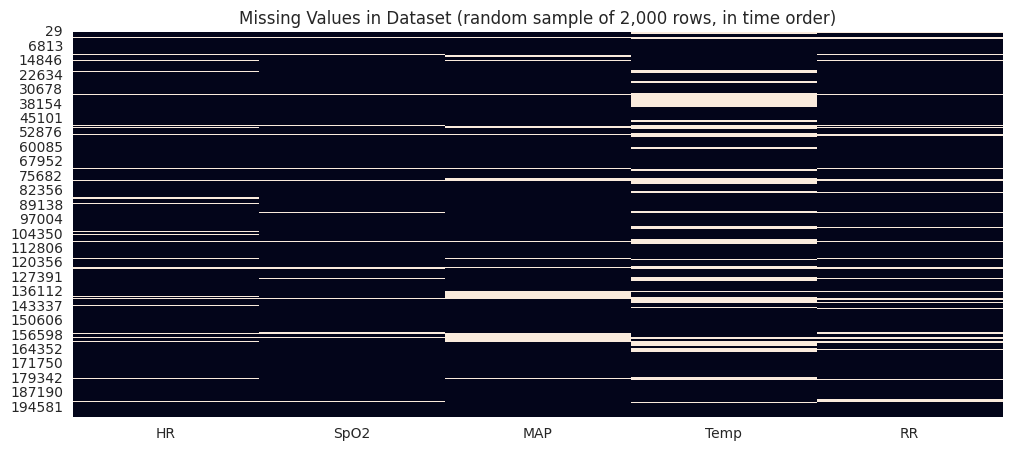

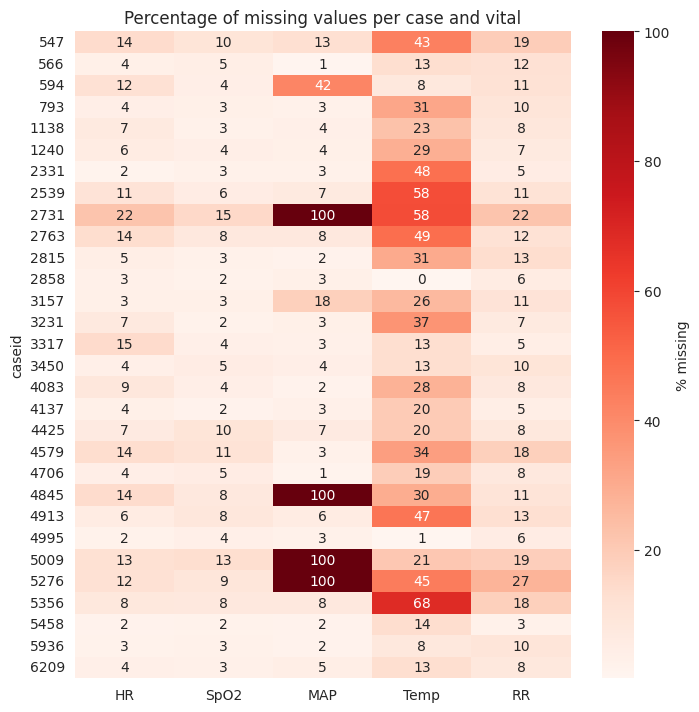

In [6]:
plt.figure(figsize=(12, 5))
sns.heatmap(df[VITALS].sample(min(2000, len(df)), random_state=0).sort_index().isnull(), cbar=False)
plt.title("Missing Values in Dataset (random sample of 2,000 rows, in time order)")
plt.show()

# Is missingness the same for every patient?
miss_case = df.groupby("caseid")[VITALS].apply(lambda g: g.isnull().mean() * 100)
plt.figure(figsize=(8, max(4, len(miss_case) * 0.28)))
sns.heatmap(miss_case, annot=True, fmt=".0f", cmap="Reds", cbar_kws={"label": "% missing"})
plt.title("Percentage of missing values per case and vital")
plt.show()

## 6. Duplicate, Data-Type and Inconsistent-Data Checks

* A row is only a *true* duplicate if the same case and the same timestamp appear twice.
* Identical vital values in different rows are **normal** (a stable heart rate repeats), so dropping rows that merely look alike would delete real data.
* *Inconsistent data* = values that are physiologically impossible (e.g. SpO₂ above 100 %, MAP below 20 mmHg), which indicate sensor errors.

In [7]:
dup_key = df.duplicated(["caseid", "time_s"]).sum()
look_alike = df[VITALS].dropna().duplicated().sum()
print("Duplicate (caseid, time) records:", dup_key)
print("Rows that merely repeat earlier vital values (NOT removed, legitimate):", look_alike)
df = df.drop_duplicates(["caseid", "time_s"]).copy()

print("\nData types:")
display(df.dtypes.to_frame("Data Type"))

print("\nUnique values:")
display(df.nunique().to_frame("Unique Values"))

Duplicate (caseid, time) records: 0
Rows that merely repeat earlier vital values (NOT removed, legitimate): 100816

Data types:


,Data Type
caseid,int64
time_s,int64
HR,float64
SpO2,float64
MAP,float64
Temp,float64
RR,float64
age,float64
sex,object
department,object



Unique values:


,Unique Values
caseid,30
time_s,15377
HR,142
SpO2,43
MAP,386
Temp,196
RR,44
age,23
sex,2
department,4


In [8]:
PLAUSIBLE = {"HR": (20, 250), "SpO2": (50, 100), "MAP": (20, 250), "Temp": (25, 45), "RR": (1, 60)}

rows = []
for v, (lo, hi) in PLAUSIBLE.items():
    rows.append({"Vital": v, "Allowed range": f"{lo}-{hi} {UNITS[v]}",
                 "Below": int((df[v] < lo).sum()), "Above": int((df[v] > hi).sum())})
inconsistent = pd.DataFrame(rows).set_index("Vital")
inconsistent["Share of readings %"] = ((inconsistent.Below + inconsistent.Above) / df[VITALS].notna().sum() * 100).round(3)
display(inconsistent)

# Impossible values -> NaN (they are sensor errors, not measurements)
for v, (lo, hi) in PLAUSIBLE.items():
    df.loc[(df[v] < lo) | (df[v] > hi), v] = np.nan

# Temperature probe warm-up: during the first 10 minutes the probe is still equilibrating
warm = df["time_s"] < 600
print("Temperature readings below 35 °C in the first 10 min (probe warm-up):", int((warm & (df.Temp < 35)).sum()))
print("Temperature readings below 35 °C after 10 min:", int((~warm & (df.Temp < 35)).sum()))
df.loc[warm, "Temp"] = np.nan

,Allowed range,Below,Above,Share of readings %
Vital,,,,
HR,20-250 beats/min,238,0,0.127
SpO2,50-100 %,7,0,0.004
MAP,20-250 mmHg,11227,1134,6.799
Temp,25-45 °C,5345,0,3.492
RR,1-60 breaths/min,202,0,0.111


Temperature readings below 35 °C in the first 10 min (probe warm-up): 302
Temperature readings below 35 °C after 10 min: 10548


## 7. Handle Missing Values

**Why not median imputation?** Filling gaps with the column median would create long flat, fake stretches, shrink the variance and weaken the real correlations between vitals. A time series needs time-aware handling:

1. **Bridge short gaps** by carrying the last reading forward *within the same patient*, only for a limited time (10 s for HR/SpO₂/MAP, 20 s for RR, 120 s for the slowly changing temperature).
2. Keep a **complete-case table** (all five vitals present) for statistics and correlations, and keep the gap-preserving table `df_ts` for time-series plots.
3. Categorical patient information (sex, department, ASA) is filled with `"Unknown"`, never with the mode.

In [9]:
numeric_columns = VITALS
GAP_S = {"HR": 10, "SpO2": 10, "MAP": 10, "Temp": 120, "RR": 20}

before_bridge = df[VITALS].isnull().mean() * 100
for v in VITALS:
    limit = max(1, GAP_S[v] // INTERVAL)
    df[v] = df.groupby("caseid")[v].transform(lambda s: s.ffill(limit=limit))
after_bridge = df[VITALS].isnull().mean() * 100

df_ts = df.copy()                                         # gaps preserved (time-series plots)
df = df.dropna(subset=VITALS).reset_index(drop=True)      # complete cases (statistics)

categorical_columns = [c for c in ["sex", "department", "asa"] if c in df.columns]
for col in categorical_columns:
    if col == "asa":
        df[col] = df[col].apply(lambda x: "Unknown" if pd.isna(x) else str(int(x)))
    else:
        df[col] = df[col].fillna("Unknown").astype(str)

print(pd.DataFrame({"Missing % before bridging": before_bridge.round(1), "after bridging": after_bridge.round(1)}))
print(f"\nComplete-case rows kept: {len(df):,} of {len(df_ts):,} ({len(df)/len(df_ts):.1%})")
print("Missing values after treatment:")
display(df[VITALS + categorical_columns].isnull().sum().to_frame("Missing Values"))

      Missing % before bridging  after bridging
HR                          6.0             5.6
SpO2                        4.5             4.0
MAP                        15.2            14.9
Temp                       26.3            25.2
RR                          9.1             8.7

Complete-case rows kept: 139,501 of 199,876 (69.8%)
Missing values after treatment:


,Missing Values
HR,0
SpO2,0
MAP,0
Temp,0
RR,0
sex,0
department,0
asa,0


## 8. Outlier Detection Using IQR

The IQR rule (values beyond Q1 − 1.5·IQR or Q3 + 1.5·IQR) is applied to every vital, as required. The key question for monitoring data is **whether those statistical outliers are errors or real clinical events**; that is checked right after.

In [10]:
numeric_data = df[numeric_columns]

Q1 = numeric_data.quantile(0.25)
Q3 = numeric_data.quantile(0.75)
IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outlier_mask = (numeric_data < lower_limit) | (numeric_data > upper_limit)
outlier_count = outlier_mask.sum()

print("Q1:");  display(Q1)
print("Q3:");  display(Q3)
print("IQR:"); display(IQR)
print("Lower / upper limits:")
display(pd.DataFrame({"lower": lower_limit.round(2), "upper": upper_limit.round(2)}))
print("Outliers:")
display(pd.DataFrame({"Outlier Count": outlier_count,
                      "Outlier %": (outlier_count / len(df) * 100).round(2)}))

Q1:


,0.25
HR,61.000000
SpO2,100.000000
MAP,73.000000
Temp,35.600002
RR,12.000000


Q3:


,0.75
HR,85.000000
SpO2,100.000000
MAP,91.000000
Temp,36.400002
RR,16.000000


IQR:


,0
HR,24.000000
SpO2,0.000000
MAP,18.000000
Temp,0.799999
RR,4.000000


Lower / upper limits:


,lower,upper
HR,25.0,121.0
SpO2,100.0,100.0
MAP,46.0,118.0
Temp,34.4,37.6
RR,6.0,22.0


Outliers:


,Outlier Count,Outlier %
HR,706,0.51
SpO2,25129,18.01
MAP,3314,2.38
Temp,7802,5.59
RR,196,0.14


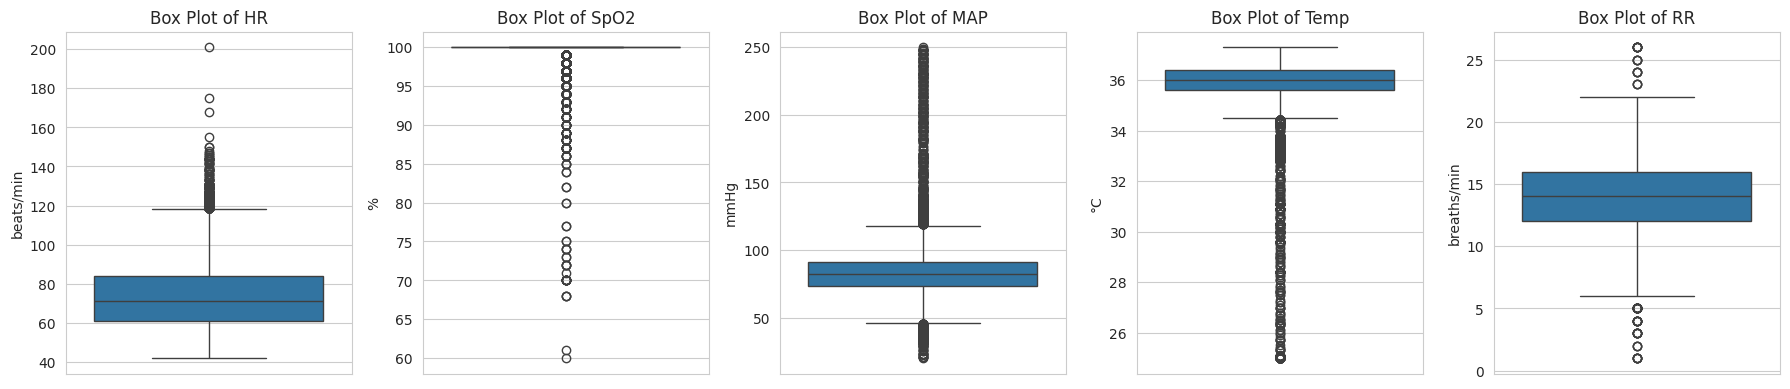

In [11]:
fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for ax, col in zip(axes, numeric_columns):
    sns.boxplot(y=df[col].sample(min(50000, len(df)), random_state=0), ax=ax)
    ax.set_title(f"Box Plot of {col}"); ax.set_ylabel(UNITS[col])
plt.tight_layout(); plt.show()

### Are the IQR outliers errors or real events?

Compare the statistical outliers with the **clinically abnormal** ranges (HR < 50 or > 100, SpO₂ < 92, MAP < 60 or > 120, Temp < 35 or > 38, RR < 8 or > 20).

In [12]:
ABNORMAL = {"HR": (50, 100), "SpO2": (92, np.inf), "MAP": (60, 120), "Temp": (35, 38), "RR": (8, 20)}

rows = []
for v in VITALS:
    lo, hi = ABNORMAL[v]
    clin_abn = (df[v] < lo) | (df[v] > hi)
    both = outlier_mask[v] & clin_abn
    rows.append({"Vital": v, "IQR outliers": int(outlier_mask[v].sum()), "Clinically abnormal": int(clin_abn.sum()),
                 "IQR outliers that are clinically abnormal %": round(both.sum() / max(outlier_mask[v].sum(), 1) * 100, 1)})
overlap_tbl = pd.DataFrame(rows).set_index("Vital")
display(overlap_tbl)
iqr_total = int(outlier_mask.to_numpy().sum())
both_total = int(sum(((outlier_mask[v]) & ((df[v] < ABNORMAL[v][0]) | (df[v] > ABNORMAL[v][1]))).sum() for v in VITALS))
overlap_pct = both_total / max(iqr_total, 1) * 100
print(f"Overall: {overlap_pct:.1f}% of IQR outliers are also clinically abnormal.")
print("Reading: a high percentage means the IQR 'outliers' are mostly genuine physiological events, not errors.")

,IQR outliers,Clinically abnormal,IQR outliers that are clinically abnormal %
Vital,,,
HR,706,13948,100.0
SpO2,25129,281,1.1
MAP,3314,9074,94.1
Temp,7802,10883,100.0
RR,196,472,100.0


Overall: 32.6% of IQR outliers are also clinically abnormal.
Reading: a high percentage means the IQR 'outliers' are mostly genuine physiological events, not errors.


### Remove IQR outliers?

**Decision: not removed by default.** Extreme blood pressure, heart rate and especially SpO₂ values are exactly the events this project wants to find. SpO₂ sits close to 100 % almost all the time, so its IQR is tiny and *every* real desaturation is flagged as an "outlier". Only the physiologically impossible readings were removed (section 6).

The switch below lets you see the effect of removing them anyway.

In [13]:
REMOVE_IQR_OUTLIERS = False          # set True only to demonstrate the effect

would_remove = outlier_mask.any(axis=1)
print(f"Rows that IQR removal would delete: {would_remove.sum():,} ({would_remove.mean():.1%} of the data)")

if REMOVE_IQR_OUTLIERS:
    df_clean = df[~would_remove].copy()
    print("Before outlier removal:", df.shape)
    print("After outlier removal:", df_clean.shape)
    df = df_clean.copy()
else:
    print("Kept all rows (clinically meaningful extremes preserved).")

Rows that IQR removal would delete: 35,337 (25.3% of the data)
Kept all rows (clinically meaningful extremes preserved).


## 9. Final Data-Quality Check

In [14]:
print("Final shape:", df.shape)
print("Missing values:")
display(df.isnull().sum())
print("Duplicate (caseid, time) records:", df.duplicated(["caseid", "time_s"]).sum())
print("Impossible values left:", int(sum(((df[v] < lo) | (df[v] > hi)).sum() for v, (lo, hi) in PLAUSIBLE.items())))

Final shape: (139501, 11)
Missing values:


,0
caseid,0
time_s,0
HR,0
SpO2,0
MAP,0
Temp,0
RR,0
age,0
sex,0
department,0


Duplicate (caseid, time) records: 0
Impossible values left: 0


## 10. Statistical Analysis

Besides the usual summary, the table shows **skewness** (asymmetry) and the **percentage of time each vital spent outside its normal clinical range**.

In [15]:
for v in VITALS:
    lo, hi = ABNORMAL[v]
    df[f"{v}_status"] = np.select([df[v] < lo, df[v] > hi], ["Low", "High"], "Normal")

display(df[numeric_columns].describe().T)

stats = pd.DataFrame({
    "Mean": df[numeric_columns].mean(),
    "Median": df[numeric_columns].median(),
    "Std Dev": df[numeric_columns].std(),
    "Minimum": df[numeric_columns].min(),
    "Maximum": df[numeric_columns].max(),
    "Skewness": df[numeric_columns].skew(),
    "% time abnormal": [(df[f"{v}_status"] != "Normal").mean() * 100 for v in VITALS],
}).round(2)
display(stats)

,count,mean,std,min,25%,50%,75%,max
HR,139501.0,73.686755,16.353515,41.0,61.000000,71.0,85.000000,214.000000
SpO2,139501.0,99.670612,1.109130,60.0,100.000000,100.0,100.000000,100.000000
MAP,139501.0,82.885062,17.277249,20.0,73.000000,82.0,91.000000,250.000000
Temp,139501.0,35.832856,1.039605,25.0,35.600002,36.0,36.400002,37.299999
RR,139501.0,14.280650,2.319216,1.0,12.000000,14.0,16.000000,26.000000


,Mean,Median,Std Dev,Minimum,Maximum,Skewness,% time abnormal
HR,73.69,71.0,16.35,41.0,214.0,0.71,10.00
SpO2,99.67,100.0,1.11,60.0,100.0,-11.83,0.20
MAP,82.89,82.0,17.28,20.0,250.0,2.41,6.50
Temp,35.83,36.0,1.04,25.0,37.3,-4.84,7.80
RR,14.28,14.0,2.32,1.0,26.0,-0.24,0.34


## 11. Univariate Analysis – Histograms

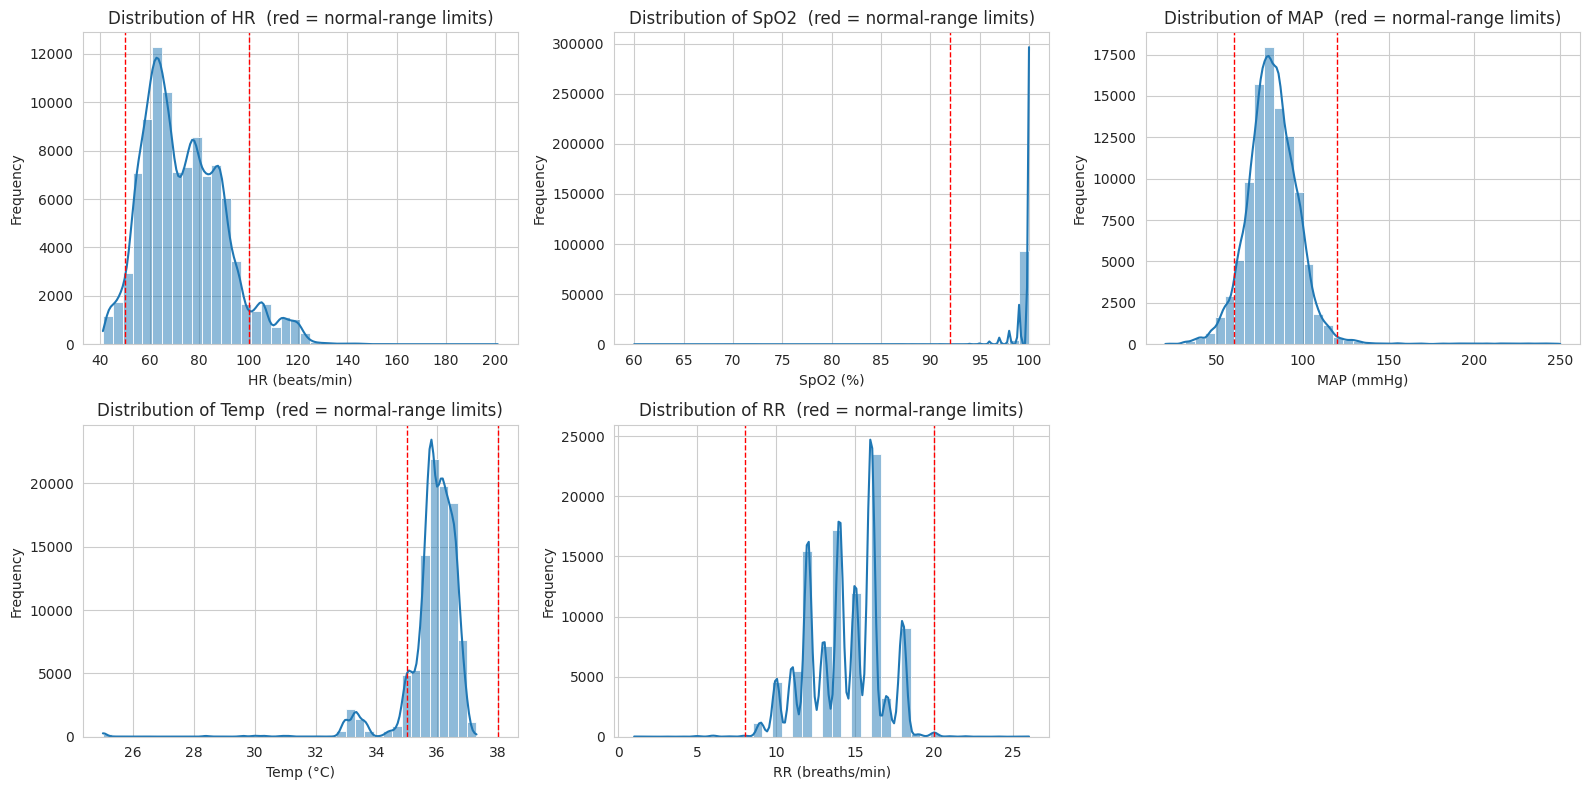

In [16]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
smp = df.sample(min(100000, len(df)), random_state=0)
for ax, col in zip(axes.ravel(), numeric_columns):
    sns.histplot(smp[col], kde=True, ax=ax, bins=40)
    for lim in ABNORMAL[col]:
        if np.isfinite(lim): ax.axvline(lim, color="red", ls="--", lw=1)
    ax.set_title(f"Distribution of {col}  (red = normal-range limits)")
    ax.set_xlabel(f"{col} ({UNITS[col]})"); ax.set_ylabel("Frequency")
axes.ravel()[-1].axis("off")
plt.tight_layout(); plt.show()

## 12. Univariate Analysis – Count Plots

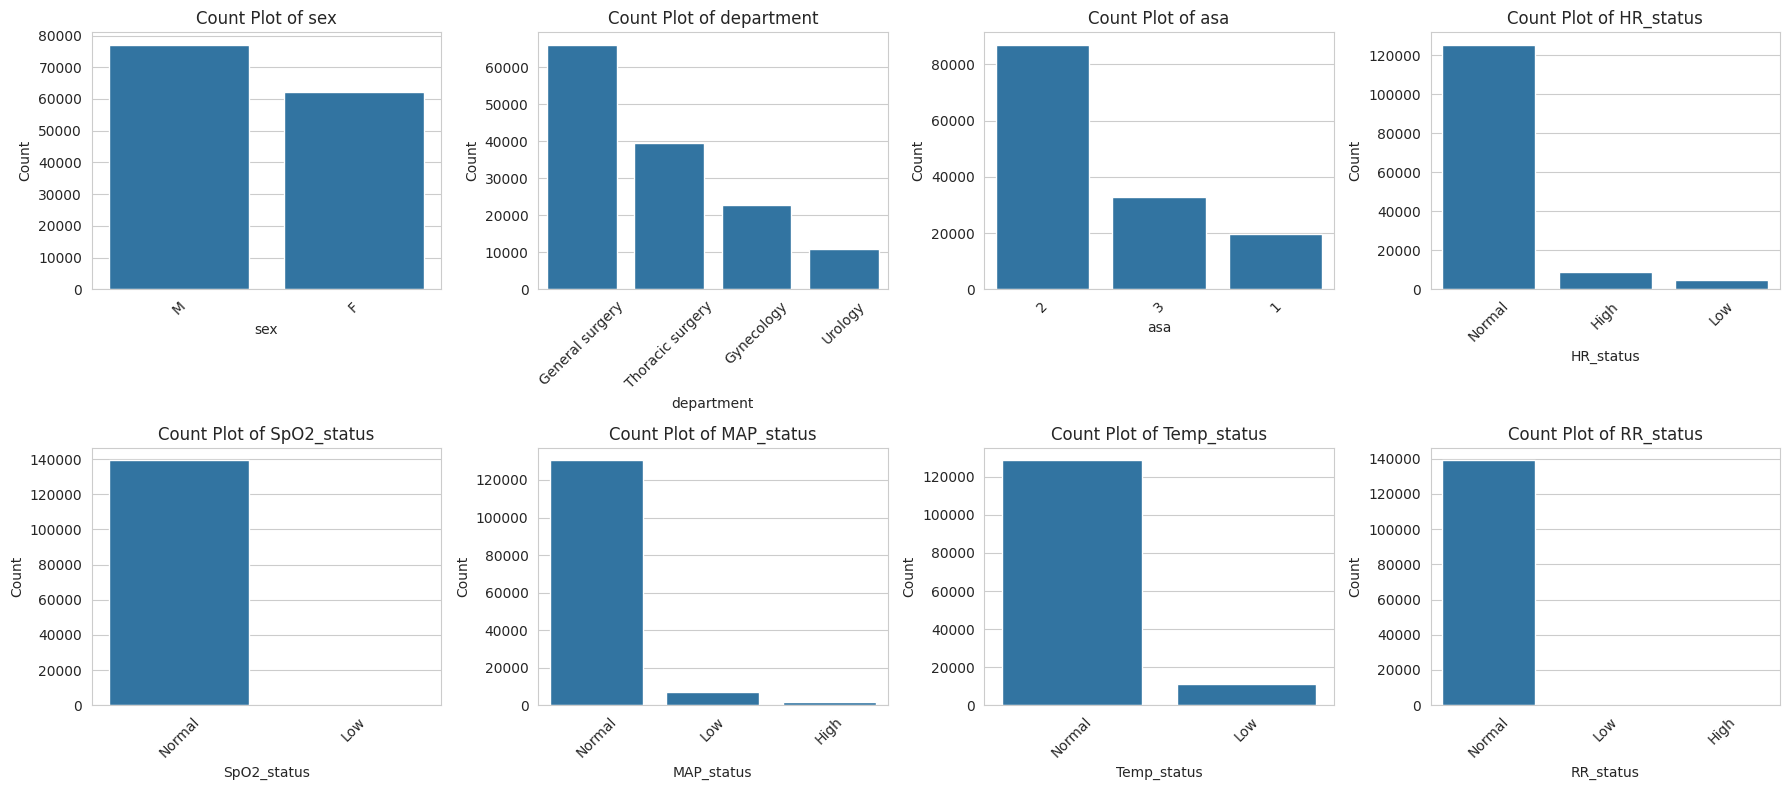

In [17]:
count_cols = categorical_columns + [f"{v}_status" for v in VITALS]
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), count_cols):
    if df[col].nunique() <= 20:
        sns.countplot(data=df, x=col, order=df[col].value_counts().index, ax=ax)
        ax.set_title(f"Count Plot of {col}"); ax.set_xlabel(col); ax.set_ylabel("Count")
        ax.tick_params(axis="x", rotation=45)
for ax in axes.ravel()[len(count_cols):]:
    ax.axis("off")
plt.tight_layout(); plt.show()

## 13. Bivariate Analysis – Scatter Plots

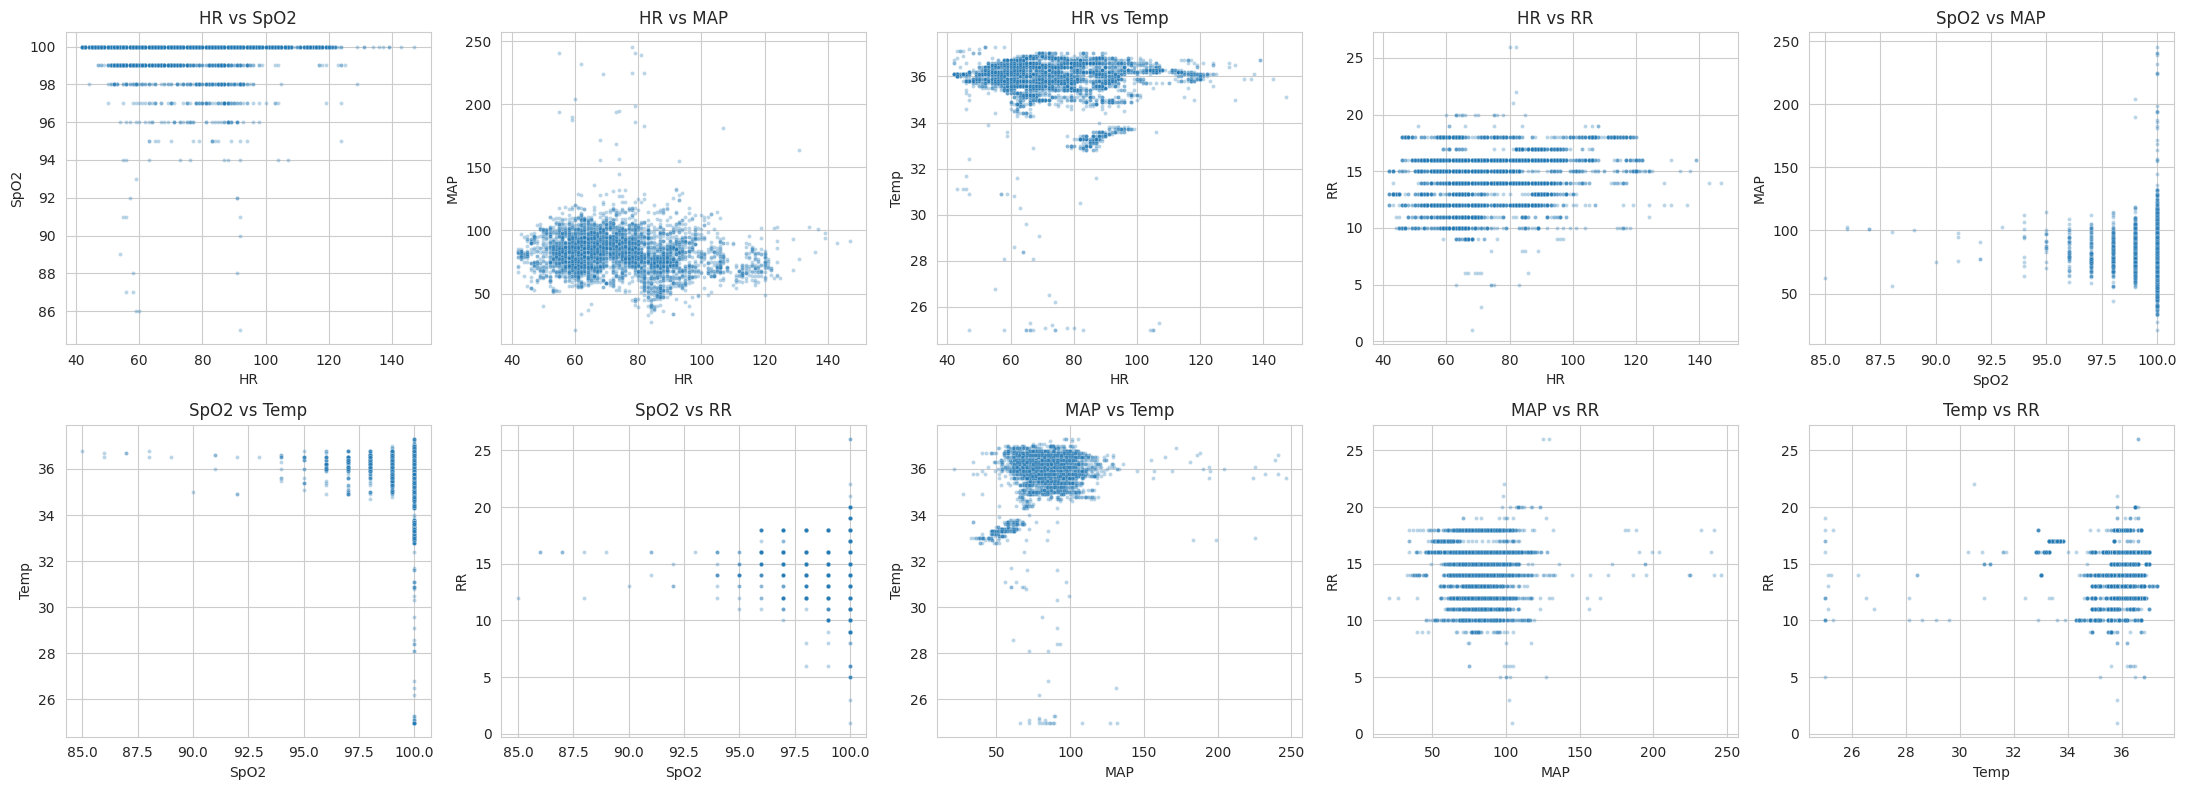

In [18]:
smp = df.sample(min(5000, len(df)), random_state=1)
pairs_list = [(VITALS[i], VITALS[j]) for i in range(5) for j in range(i + 1, 5)]
fig, axes = plt.subplots(2, 5, figsize=(22, 8))
for ax, (x, y) in zip(axes.ravel(), pairs_list):
    sns.scatterplot(data=smp, x=x, y=y, s=8, alpha=0.3, ax=ax)
    ax.set_title(f"{x} vs {y}")
plt.tight_layout(); plt.show()

## 14. Bivariate Analysis – Categorical vs Numerical

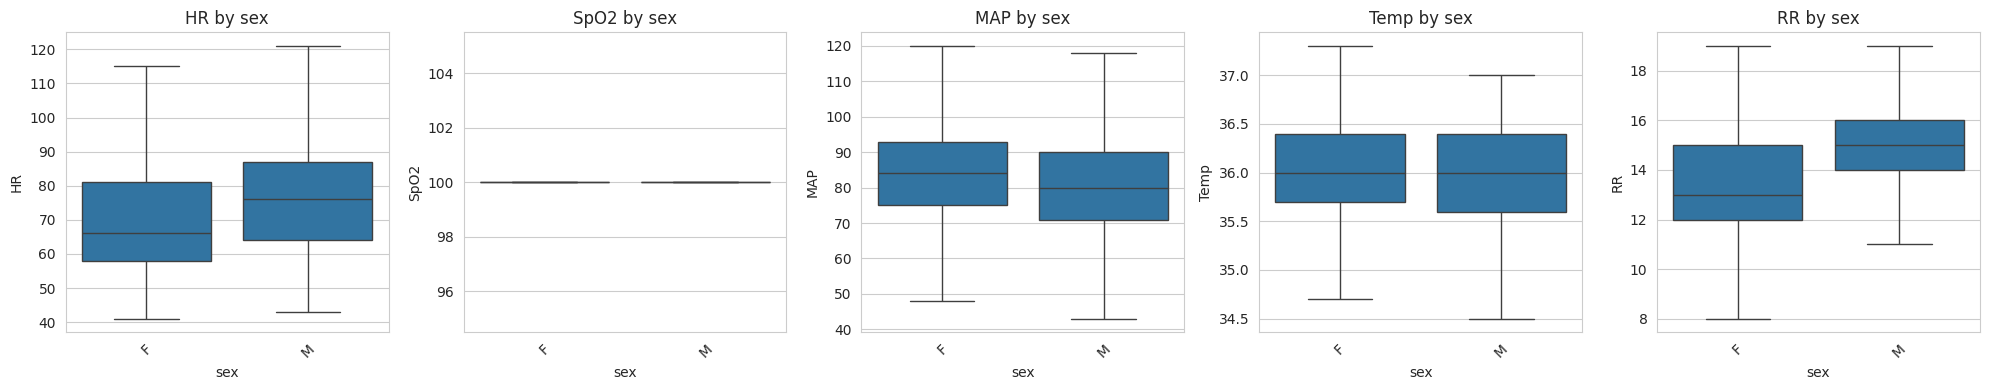

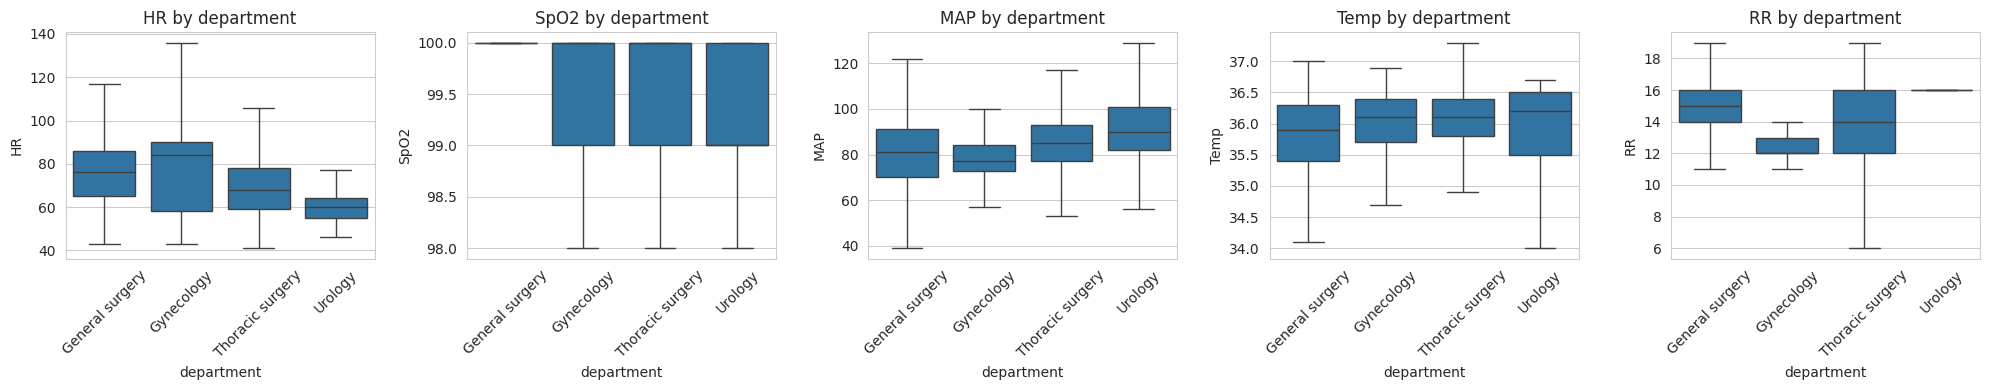

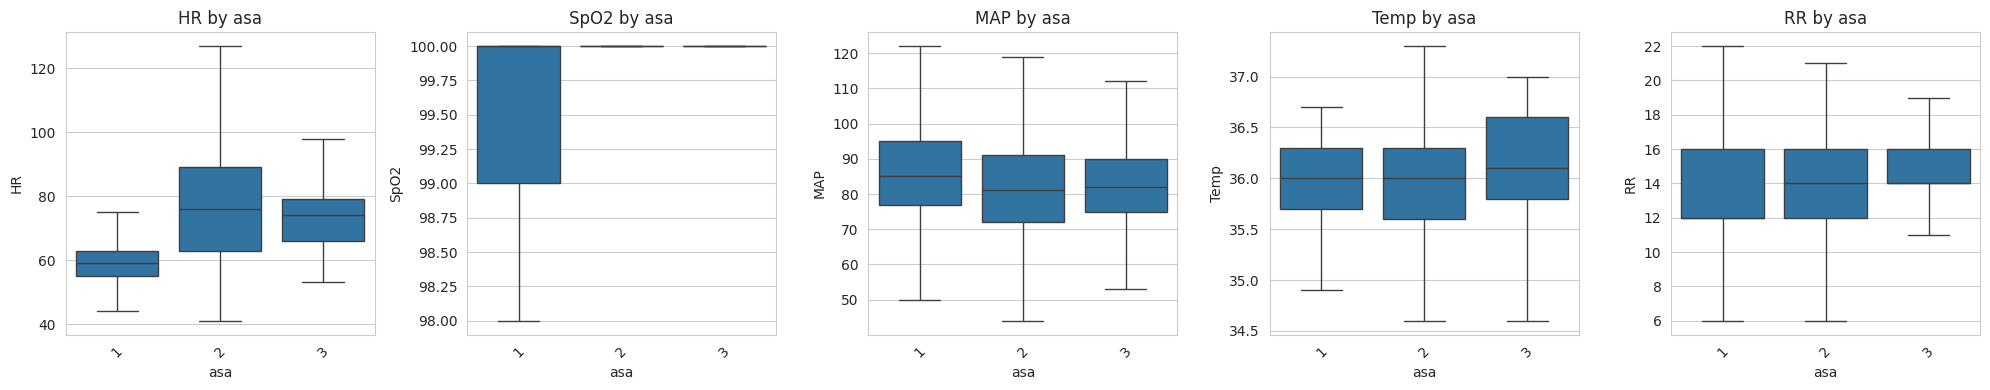

In [19]:
smp = df.sample(min(60000, len(df)), random_state=2)
for cat in categorical_columns:
    if df[cat].nunique() <= 15:
        fig, axes = plt.subplots(1, 5, figsize=(20, 4))
        order = sorted(df[cat].unique())
        for ax, num in zip(axes, numeric_columns):
            sns.boxplot(data=smp, x=cat, y=num, order=order, showfliers=False, ax=ax)
            ax.set_title(f"{num} by {cat}"); ax.tick_params(axis="x", rotation=45)
        plt.tight_layout(); plt.show()

## 15. Correlation Analysis and Heatmap

Three views are shown:
* **Pearson** (linear) and **Spearman** (rank) correlation over all rows;
* **Within-patient** correlation, after subtracting each patient's own average. This removes differences *between* patients (a patient with high blood pressure all along) and shows how the vitals move *together over time* in the same patient.

,HR,SpO2,MAP,Temp,RR
HR,1.000000,-0.032559,-0.143107,-0.056834,0.224514
SpO2,-0.032559,1.000000,-0.009808,-0.080637,-0.061460
MAP,-0.143107,-0.009808,1.000000,0.117519,-0.003987
Temp,-0.056834,-0.080637,0.117519,1.000000,0.003463
RR,0.224514,-0.061460,-0.003987,0.003463,1.000000


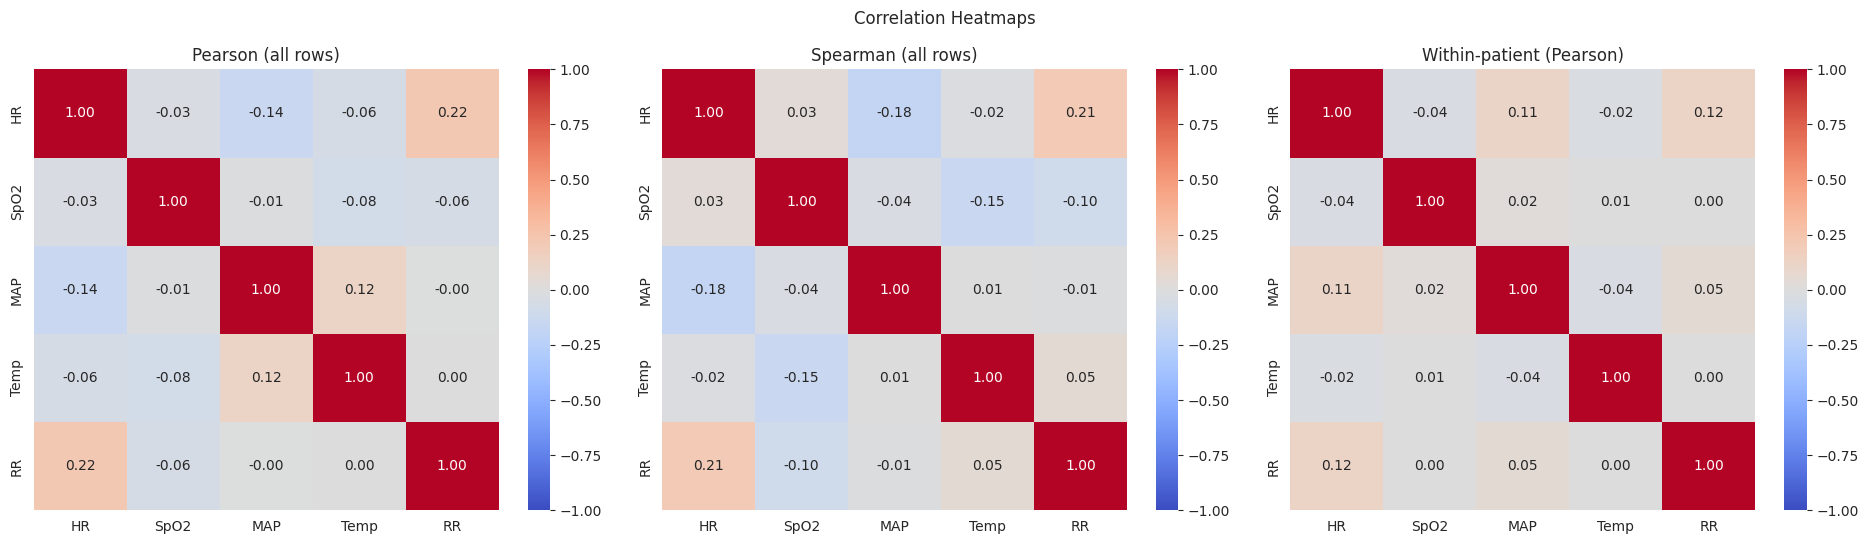

In [20]:
corr = df[numeric_columns].corr()
corr_s = df[numeric_columns].corr(method="spearman")
within = df[numeric_columns] - df.groupby("caseid")[numeric_columns].transform("mean")
corr_w = within.corr()
display(corr)

fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))
for ax, c, t in zip(axes, [corr, corr_s, corr_w], ["Pearson (all rows)", "Spearman (all rows)", "Within-patient (Pearson)"]):
    sns.heatmap(c, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, ax=ax)
    ax.set_title(t)
plt.suptitle("Correlation Heatmaps"); plt.tight_layout(); plt.show()

## 16. Strongest Correlations

In [21]:
def top_pairs(c, n=10):
    return (c.where(np.triu(np.ones(c.shape), k=1).astype(bool)).stack()
             .sort_values(key=lambda x: x.abs(), ascending=False).head(n))

pairs = top_pairs(corr)
display(pd.DataFrame({"Pearson": pairs, "Spearman": [corr_s.loc[a, b] for a, b in pairs.index],
                      "Within-patient": [corr_w.loc[a, b] for a, b in pairs.index]}).round(3))

Pearson  Spearman  Within-patient
HR   RR      0.225     0.207           0.121
     MAP    -0.143    -0.179           0.110
MAP  Temp    0.118     0.006          -0.038
SpO2 Temp   -0.081    -0.146           0.007
     RR     -0.061    -0.099           0.001
HR   Temp   -0.057    -0.020          -0.024
     SpO2   -0.033     0.033          -0.036
SpO2 MAP    -0.010    -0.038           0.023
MAP  RR     -0.004    -0.010           0.050
Temp RR      0.003     0.053           0.000

## 17. Pair Plot (multivariate view)

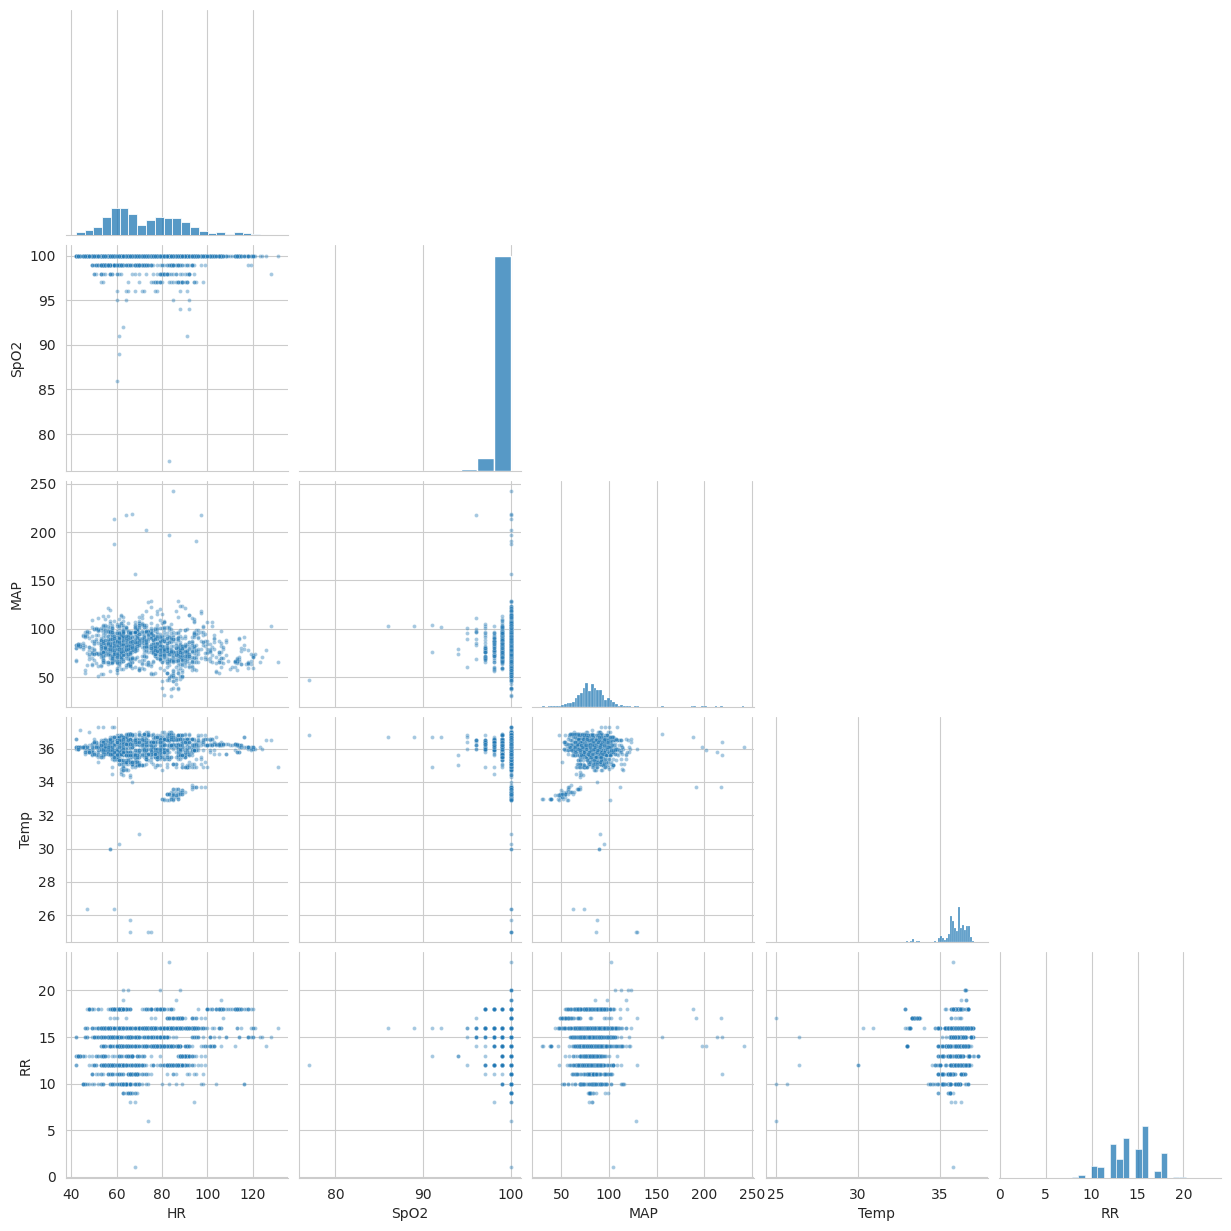

In [22]:
pair_cols = numeric_columns
if len(pair_cols) >= 2:
    sample = df.sample(min(1500, len(df)), random_state=3)
    sns.pairplot(sample[pair_cols].dropna(), corner=True, plot_kws={"s": 8, "alpha": 0.4})
    plt.show()
else:
    print("Not enough numerical columns for a pair plot.")

## 17b. Additional Analysis – Time-Series Patterns (specific to monitoring data)

Monitoring data are *ordered in time*, which the standard EDA steps ignore. Three extra views: one patient's full recording, the typical trend over the surgery, and how often each vital is abnormal for different patient groups.

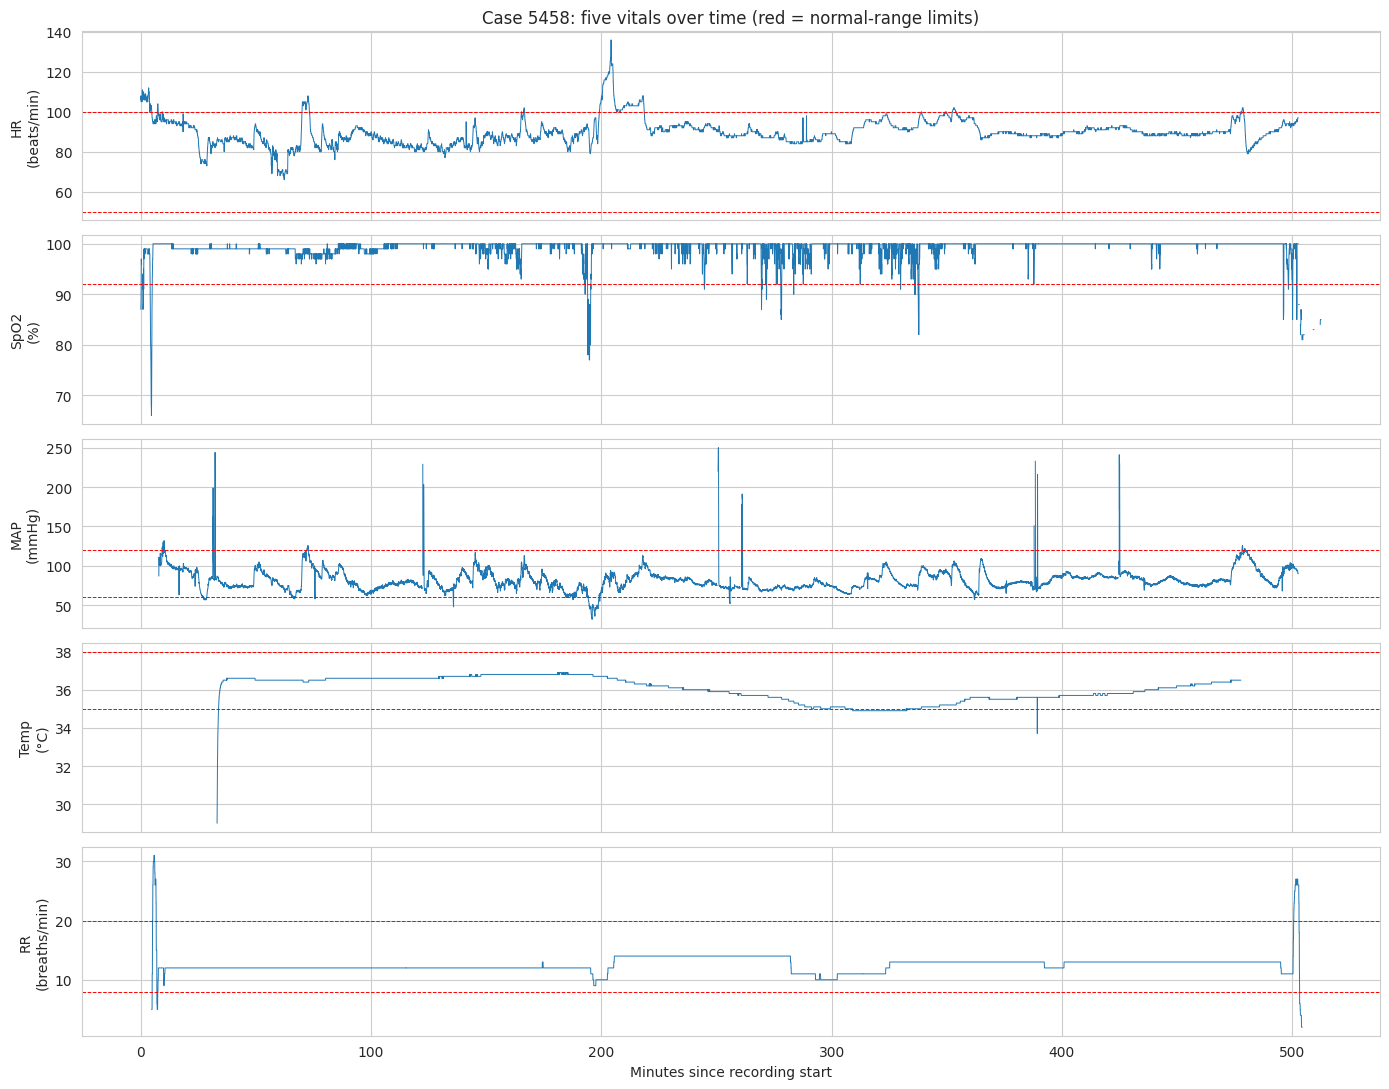

In [23]:
# (a) One complete recording, gaps preserved
best = df.groupby("caseid").size().idxmax()
d = df_ts[df_ts.caseid == best]
fig, axes = plt.subplots(5, 1, figsize=(14, 11), sharex=True)
for ax, v in zip(axes, VITALS):
    ax.plot(d.time_s / 60, d[v], lw=0.7)
    for lim in ABNORMAL[v]:
        if np.isfinite(lim): ax.axhline(lim, ls="--", lw=0.7, color="red")
    ax.set_ylabel(f"{v}\n({UNITS[v]})")
axes[0].set_title(f"Case {best}: five vitals over time (red = normal-range limits)")
axes[-1].set_xlabel("Minutes since recording start")
plt.tight_layout(); plt.show()

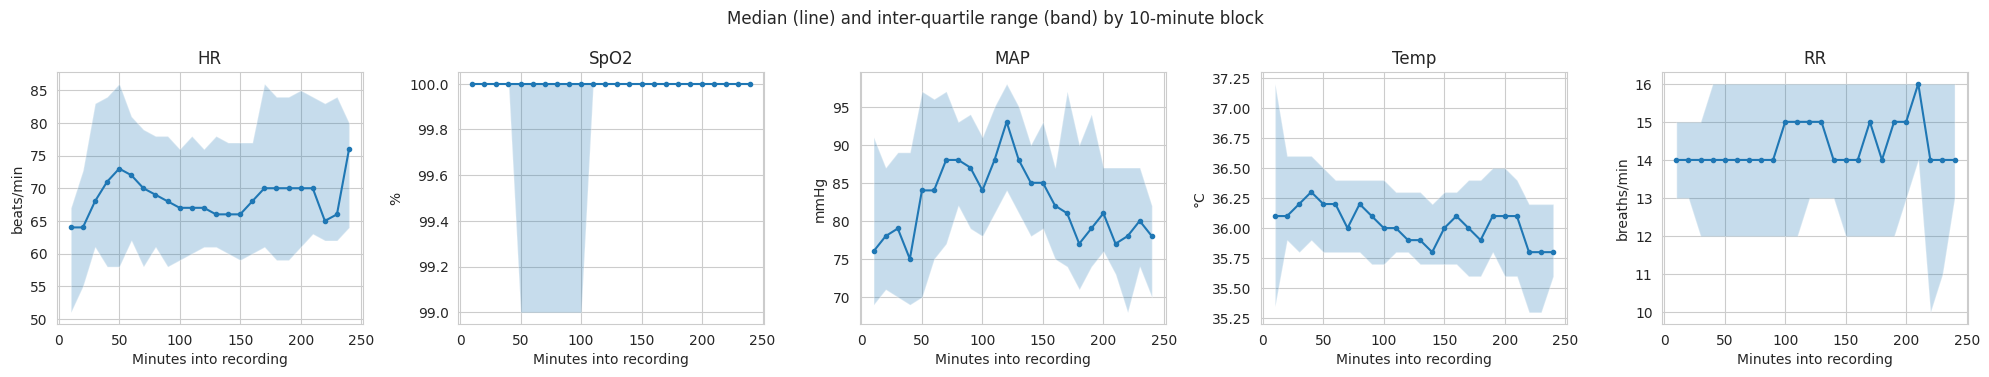

In [24]:
# (b) Typical trend: median and inter-quartile band per 10-minute block
df["elapsed_min"] = df["time_s"] / 60
df["block"] = (df["elapsed_min"] // 10 * 10).astype(int)
trend = df[df.block <= 240].groupby("block")[VITALS].agg(["median", lambda s: s.quantile(.25), lambda s: s.quantile(.75)])
fig, axes = plt.subplots(1, 5, figsize=(20, 3.8))
for ax, v in zip(axes, VITALS):
    ax.plot(trend.index, trend[(v, "median")], marker="o", ms=3)
    ax.fill_between(trend.index, trend[(v, "<lambda_0>")], trend[(v, "<lambda_1>")], alpha=0.25)
    ax.set_title(v); ax.set_xlabel("Minutes into recording"); ax.set_ylabel(UNITS[v])
plt.suptitle("Median (line) and inter-quartile range (band) by 10-minute block"); plt.tight_layout(); plt.show()

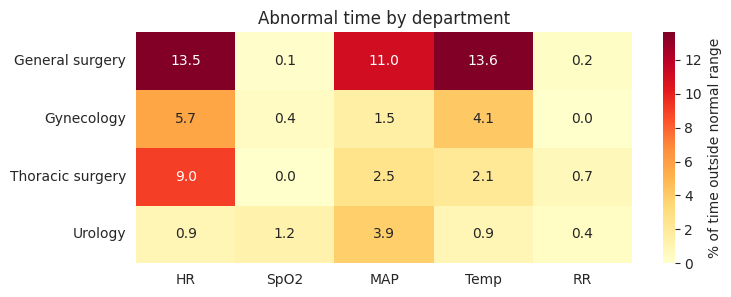

In [25]:
# (c) Share of time abnormal, by patient group
group_col = "department" if "department" in df.columns else None
if group_col:
    ab = pd.DataFrame({v: (df[f"{v}_status"] != "Normal") for v in VITALS}).groupby(df[group_col]).mean() * 100
    plt.figure(figsize=(8, max(3, 0.6 * len(ab))))
    sns.heatmap(ab, annot=True, fmt=".1f", cmap="YlOrRd", cbar_kws={"label": "% of time outside normal range"})
    plt.title(f"Abnormal time by {group_col}"); plt.ylabel(""); plt.show()

## 18. Key Findings

The cell below fills the findings **from your own results**, so the numbers always match the outputs above. Copy them into your report and add your own interpretation.

In [26]:
n_raw, c_raw = df_raw.shape
miss_txt = ", ".join(f"{v} {missing.loc[v, 'Missing Percentage']:.1f}%" for v in VITALS)
top_out = outlier_count.sort_values(ascending=False)
skew = stats["Skewness"]; most_skew = skew.abs().idxmax()
a, b = pairs.index[0]; strongest = pairs.iloc[0]
(a2, b2) = top_pairs(corr_w, 1).index[0]; strongest_w = top_pairs(corr_w, 1).iloc[0]
abn = stats["% time abnormal"]
t_first = df.loc[df.block.between(10, 30), "Temp"].median(); t_last = df.loc[df.block.between(150, 240), "Temp"].median()

findings = f"""
1. Dataset size: {n_raw:,} rows and {c_raw} columns as loaded ({df_raw.caseid.nunique()} patients); {len(df):,} rows x {df.shape[1]} columns after cleaning ({len(df)/n_raw:.0%} of the original rows).
2. Missing values (before treatment): {miss_txt}.
3. Duplicate records: {dup_key} true duplicates (same case and time); {inconsistent[['Below','Above']].sum().sum()} physiologically impossible readings were set to missing.
4. Outliers (IQR) were found most in: {top_out.index[0]} ({top_out.iloc[0]:,} rows, {top_out.iloc[0]/len(df):.1%}); fewest in {top_out.index[-1]}.
   {overlap_pct:.0f}% of IQR outliers are also clinically abnormal ({"so most are real physiological events" if overlap_pct >= 50 else "so many are only statistical extremes"}); all were kept because impossible values had already been removed.
5. Important distribution/pattern: {most_skew} is the most skewed vital (skewness {skew[most_skew]:+.2f}); the vital that spends most time outside its normal range is {abn.idxmax()} ({abn.max():.1f}% of the time).
6. Important relationship: the within-patient correlation is strongest for {a2}-{b2} (r = {strongest_w:+.2f}).
7. Strongest correlation over all rows: {a}-{b} (Pearson r = {strongest:+.2f}).
8. Important comparison/trend: median body temperature is {t_first:.1f} °C at 10-30 min and {t_last:.1f} °C at 150-240 min into the recording.
"""
print(findings)


1. Dataset size: 199,876 rows and 11 columns as loaded (30 patients); 139,501 rows x 18 columns after cleaning (70% of the original rows).
2. Missing values (before treatment): HR 5.9%, SpO2 4.5%, MAP 9.0%, Temp 23.4%, RR 9.0%.
3. Duplicate records: 0 true duplicates (same case and time); 18153 physiologically impossible readings were set to missing.
4. Outliers (IQR) were found most in: SpO2 (25,129 rows, 18.0%); fewest in RR.
   33% of IQR outliers are also clinically abnormal (so many are only statistical extremes); all were kept because impossible values had already been removed.
5. Important distribution/pattern: SpO2 is the most skewed vital (skewness -11.83); the vital that spends most time outside its normal range is HR (10.0% of the time).
6. Important relationship: the within-patient correlation is strongest for HR-RR (r = +0.12).
7. Strongest correlation over all rows: HR-RR (Pearson r = +0.22).
8. Important comparison/trend: median body temperature is 36.1 °C at 10-30 min 

## 19. Conclusion

The cell below drafts the conclusion from your results. Edit it in your own words before submitting.

In [27]:
print(f"""
The VitalDB sample ({df_raw.caseid.nunique()} surgical patients, {n_raw:,} readings of heart rate, SpO2, mean blood pressure, temperature and respiratory rate)
needed domain-aware cleaning rather than the generic steps. Missing values were treated as sensor-related gaps (not random), so short gaps were
bridged within each patient instead of being filled with the median, and {len(df)/len(df_ts):.0%} of the rows had all five vitals. Physiologically impossible values and the first ten
minutes of temperature (probe warm-up) were treated as sensor artifacts.

IQR flagged outliers in {int((outlier_count > 0).sum())} of 5 vitals; {overlap_pct:.0f}% of them also fall outside the clinical normal range ({"mostly real physiological events" if overlap_pct >= 50 else "so many are only statistical extremes"}).
They were kept: removing them would have deleted {would_remove.mean():.1%} of the data, including the situations a monitoring study is meant to find.

{most_skew} was the most skewed vital and {abn.idxmax()} spent the most time outside its normal range ({abn.max():.1f}%). The strongest overall correlation was {a}-{b} (r = {strongest:+.2f});
within the same patient, {a2}-{b2} moved together most (r = {strongest_w:+.2f}). Such multi-vital agreement is useful for telling genuine physiological change
(several vitals move together) from a single-sensor artifact, which is the next step of this project.
""")


The VitalDB sample (30 surgical patients, 199,876 readings of heart rate, SpO2, mean blood pressure, temperature and respiratory rate)
needed domain-aware cleaning rather than the generic steps. Missing values were treated as sensor-related gaps (not random), so short gaps were
bridged within each patient instead of being filled with the median, and 70% of the rows had all five vitals. Physiologically impossible values and the first ten
minutes of temperature (probe warm-up) were treated as sensor artifacts.

IQR flagged outliers in 5 of 5 vitals; 33% of them also fall outside the clinical normal range (so many are only statistical extremes).
They were kept: removing them would have deleted 25.3% of the data, including the situations a monitoring study is meant to find.

SpO2 was the most skewed vital and HR spent the most time outside its normal range (10.0%). The strongest overall correlation was HR-RR (r = +0.22);
within the same patient, HR-RR moved together most (r = +0.12). Such